In [1]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters.character import RecursiveCharacterTextSplitter
import ollama
import re

/tmp/ipykernel_25214/3676925187.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


fetch data

In [2]:
def cleanText(text):
    text = re.sub(r'-\n(\w)', r'\1', text)     # re-join words hyphenated across lines
    text = text.replace('•', '\n- ')           # bullets as their own lines
    text = re.sub(r'[ \t]+', ' ', text)        # collapse spaces/tabs only
    text = re.sub(r'\n{3,}', '\n\n', text)     # cap blank lines
    return text.strip()

In [3]:
loader = PyPDFLoader("data/kejriwal-et-al-2019-knowledge-graphs-construction-management-and-querying.pdf")
loader = PyPDFLoader("data/Food_Factsheets_06_EN.pdf")
pages = loader.load()

In [4]:
for page in pages: 
    page.page_content = cleanText(page.page_content) 

split into chunks

In [5]:
splitter = RecursiveCharacterTextSplitter(chunk_size = 800, chunk_overlap= 100) # created an instance of the text splitter
chunks = splitter.split_documents(pages)

vectorize 

In [6]:
# functions & global variables 

def createEmbedding(text):
    response = ollama.embed(
    model='nomic-embed-text-v2-moe',
    input=text,
    )
    return response.embeddings[0]

In [7]:
doc_embeddings = [] # this is our list of embeddings from out document

for chunk in chunks:
    chunk_embedding = createEmbedding(chunk.page_content)
    doc_embeddings.append(chunk_embedding) 

# Creating a Knowledge graph

pass data into llm to disover relationships and nodes,  The entity and relationship types would become labels  and relationship types in the graph

In [8]:
from langchain_ollama import ChatOllama
from langchain_neo4j import Neo4jGraph, LLMGraphTransformer


In [9]:
llm = ChatOllama(model="deepseek-r1:1.5b ", temperature=0)

In [10]:
graph = Neo4jGraph(url="neo4j://127.0.0.1:7687", username="neo4j", password="neo4j123")

This will help in generating the nodes + relationships

In [11]:
transformer = LLMGraphTransformer(llm=llm)

In [12]:
chunks[0].page_content

'Food for the body and the mind\nFood is good! Knowing what it \ndoes for the body and the mind \nis key to making the right choices \nand enjoying the best of it.\nEating is necessary to provide \nenergy for the body’s functions, \nand nutrients to repair and build \ntissue, prevent sickness and \nhelp the body heal from illness. \nKnowledge of what food does \nfor the body and mind empowers \nyou to choose the right type, \nquality and quantity of food – \nthat’s the art. \n Foods, nutrients \nand their functions\n - Carbohydrates are the primary \nsource of energy for the body. We get \nthem from roots, tubers, grains, sugar, \nfruits, legumes, dairy products and \nvegetables. \n - Fats and oils are concentrated forms \nof energy, but they also help the \nabsorption of vitamins, support cell'

In [23]:
chunks[0]

Document(metadata={'producer': 'Adobe PDF Library 15.0', 'creator': 'Adobe InDesign 14.0 (Macintosh)', 'creationdate': '2019-11-05T20:04:16+00:00', 'moddate': '2019-11-05T20:04:18+00:00', 'trapped': '/False', 'source': 'data/Food_Factsheets_06_EN.pdf', 'total_pages': 9, 'page': 0, 'page_label': '1', 'id': '711daf8a6dfcb8785636337ea047371f'}, page_content='Food for the body and the mind\nFood is good! Knowing what it \ndoes for the body and the mind \nis key to making the right choices \nand enjoying the best of it.\nEating is necessary to provide \nenergy for the body’s functions, \nand nutrients to repair and build \ntissue, prevent sickness and \nhelp the body heal from illness. \nKnowledge of what food does \nfor the body and mind empowers \nyou to choose the right type, \nquality and quantity of food – \nthat’s the art. \n Foods, nutrients \nand their functions\n - Carbohydrates are the primary \nsource of energy for the body. We get \nthem from roots, tubers, grains, sugar, \nfrui

In [21]:
chunks[1]

Document(metadata={'producer': 'Adobe PDF Library 15.0', 'creator': 'Adobe InDesign 14.0 (Macintosh)', 'creationdate': '2019-11-05T20:04:16+00:00', 'moddate': '2019-11-05T20:04:18+00:00', 'trapped': '/False', 'source': 'data/Food_Factsheets_06_EN.pdf', 'total_pages': 9, 'page': 0, 'page_label': '1'}, page_content='of energy, but they also help the \nabsorption of vitamins, support cell \nmembrane health and maintain the \nimmune system. \n - Protein foods perform the main \nbody-building and repair functions \nas well as being sources of energy in \nthe absence of carbohydrates. The \nbest protein sources are animal foods \n– meat, poultry, fish, eggs, insects \nand dairy products. We also get \nprotein from such plant sources as \nbeans, peas, nuts, cereals and derived \nproducts. \n - Vitamins and minerals collectively \nare called micronutrients because \nthe body needs them in small \nquantities. But they are crucial \nfor regulating tissue growth and \nvital body functions, includ

In [13]:
graph_documents = transformer.convert_to_graph_documents([chunks[0]]) 

In [24]:
graph_documents_two = transformer.convert_to_graph_documents([chunks[1]]) 

In [28]:
graph_documents_three = transformer.convert_to_graph_documents([chunks[2]]) 

In [33]:
graph_documents_four = transformer.convert_to_graph_documents([chunks[3]]) 

In [15]:
graph.add_graph_documents(graph_documents, baseEntityLabel=True, include_source=True) # adds the knowledge graph to DB

In [25]:
graph.add_graph_documents(graph_documents_two, baseEntityLabel=True, include_source=True) # adds the knowledge graph to DB

In [30]:
graph.add_graph_documents(graph_documents_three, baseEntityLabel=True, include_source=True) # adds the knowledge graph to DB

In [34]:
graph.add_graph_documents(graph_documents_four, baseEntityLabel=True, include_source=True) # adds the knowledge graph to DB

In [17]:
graph_documents[0].relationships

[Relationship(source=Node(id='Energy Sources', type='Concept', properties={}), target=Node(id='Food', type='Entity', properties={}), type='PROVIDES', properties={}),
 Relationship(source=Node(id='Energy Sources', type='Concept', properties={}), target=Node(id='Food', type='Entity', properties={}), type='HELPS', properties={})]

In [18]:
# from neo4j_viz.neo4j import from_neo4j
# from neo4j import GraphDatabase

# driver = GraphDatabase.driver("bolt://localhost:7687", auth=("neo4j", "neo4j123"))
# result = driver.session.run("MATCH (n)-[r]->(m) RETURN n, r, m LIMIT 50")
# VG = from_neo4j(result)

# VG.render()

In [35]:
# 1. Connect to your running Neo4j database
# (this creates the "driver" — think of it as the connection/plug to the database)
from neo4j import GraphDatabase

driver = GraphDatabase.driver(
    "neo4j://localhost:7687",           # the address Neo4j listens on
    auth=("neo4j", "neo4j123")      # replace with YOUR actual password
)

# 2. Pull the graph data out of Neo4j into Python
import networkx as nx

def get_graph_from_neo4j(driver):
    G = nx.DiGraph()
    with driver.session() as session:
        result = session.run(
            "MATCH (n)-[r]->(m) RETURN n.id AS source, type(r) AS relation, m.id AS target LIMIT 50"
        )
        for record in result:
            G.add_edge(record["source"], record["target"], label=record["relation"])
    return G

G = get_graph_from_neo4j(driver)



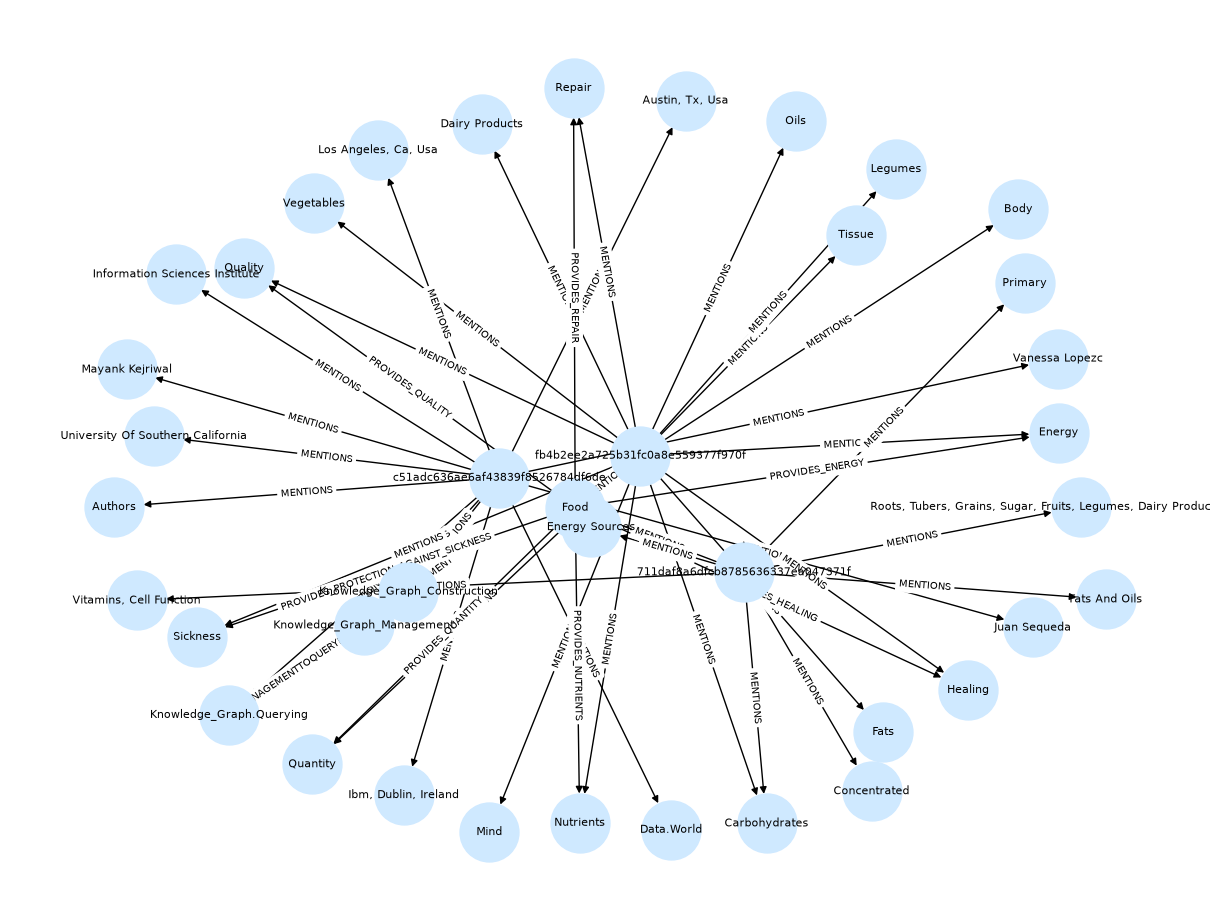

In [20]:
# Build the graph
G = get_graph_from_neo4j(driver)

# 3. Draw it
import matplotlib.pyplot as plt

# Calculate where to place each node so they don't overlap
pos = nx.spring_layout(G, seed=3)

plt.figure(figsize=(12, 9))  # size of the picture

# Draw the nodes and arrows
nx.draw(
    G, pos,
    with_labels=True,          # show node names
    node_color="#cfe9ff",      # light blue nodes
    node_size=1800,
    font_size=8,
    arrows=True                # show arrow direction
)

# Draw the relationship names on top of each arrow (e.g. "ENROLLED_IN")
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()  # actually display the picture

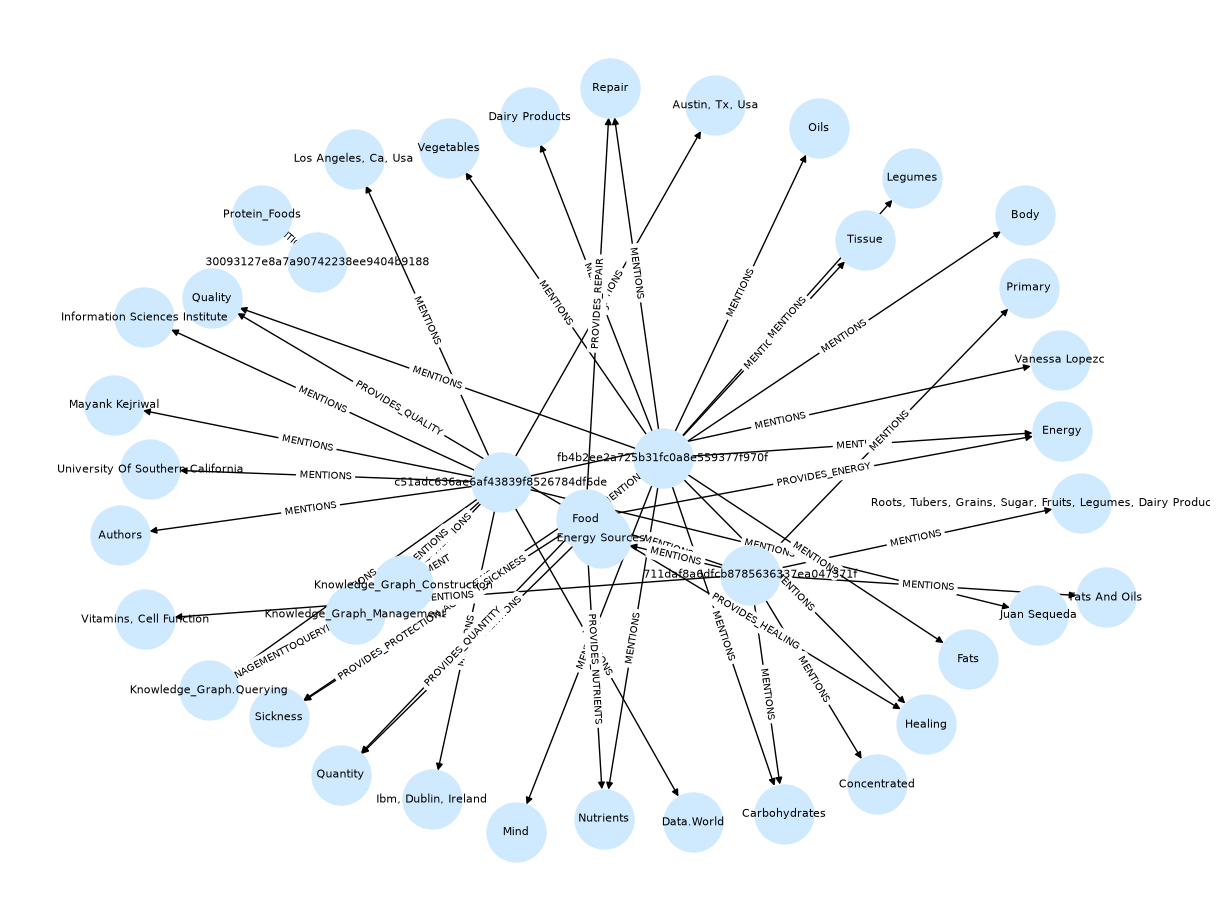

In [27]:
# Build the graph
G = get_graph_from_neo4j(driver)

# 3. Draw it
import matplotlib.pyplot as plt

# Calculate where to place each node so they don't overlap
pos = nx.spring_layout(G, seed=3)

plt.figure(figsize=(12, 9))  # size of the picture

# Draw the nodes and arrows
nx.draw(
    G, pos,
    with_labels=True,          # show node names
    node_color="#cfe9ff",      # light blue nodes
    node_size=1800,
    font_size=8,
    arrows=True                # show arrow direction
)

# Draw the relationship names on top of each arrow (e.g. "ENROLLED_IN")
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()  # actually display the picture

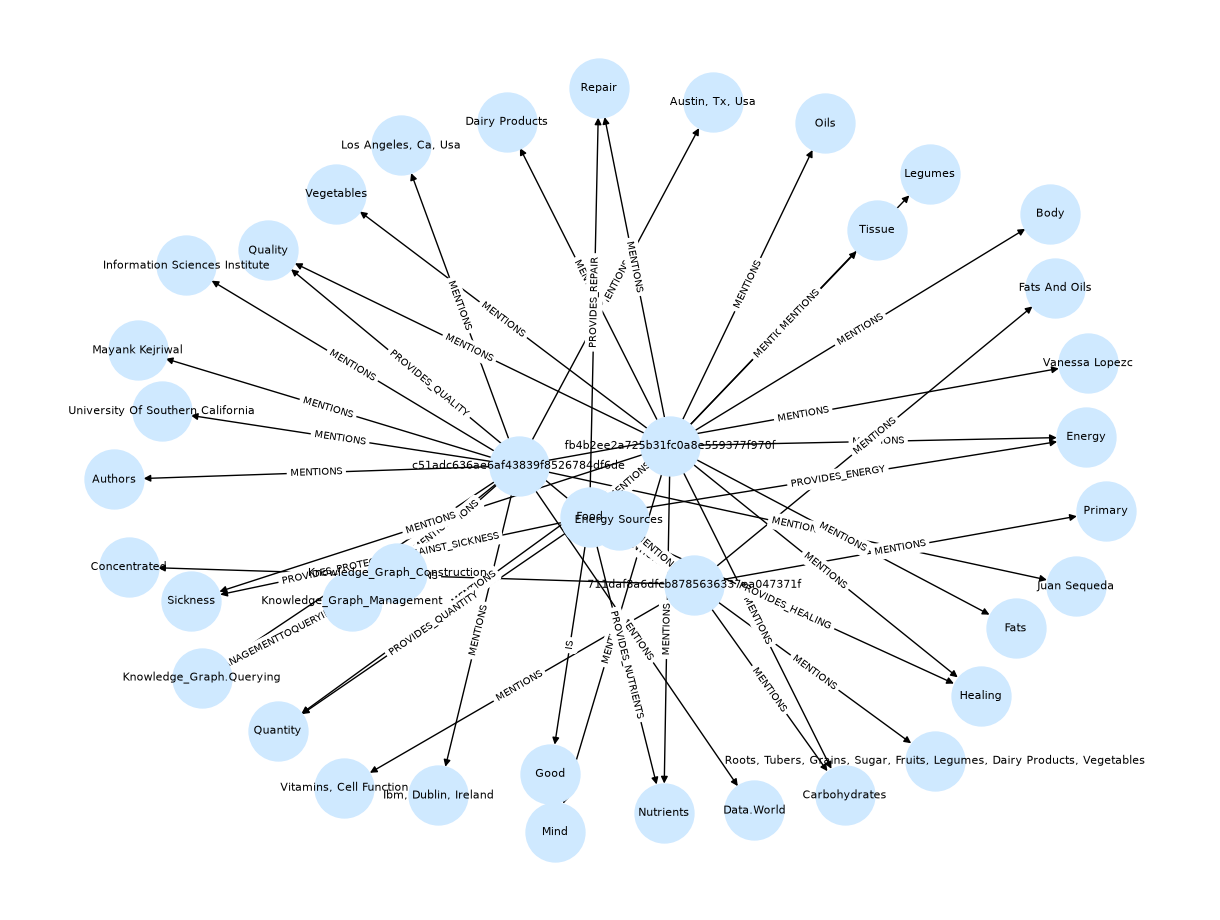

In [32]:
# Build the graph
G = get_graph_from_neo4j(driver)

# 3. Draw it
import matplotlib.pyplot as plt

# Calculate where to place each node so they don't overlap
pos = nx.spring_layout(G, seed=3)

plt.figure(figsize=(12, 9))  # size of the picture

# Draw the nodes and arrows
nx.draw(
    G, pos,
    with_labels=True,          # show node names
    node_color="#cfe9ff",      # light blue nodes
    node_size=1800,
    font_size=8,
    arrows=True                # show arrow direction
)

# Draw the relationship names on top of each arrow (e.g. "ENROLLED_IN")
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()  # actually display the picture

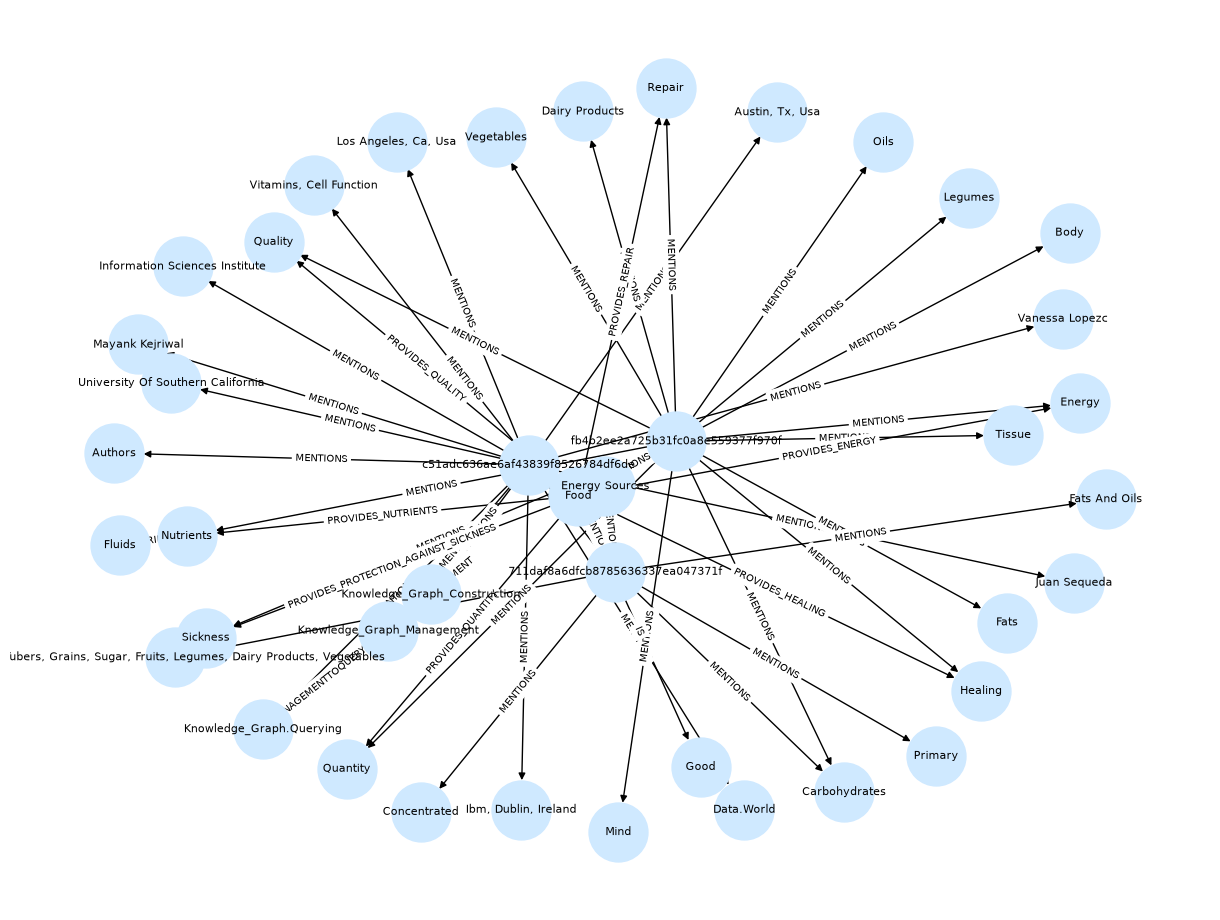

In [36]:
# Build the graph
G = get_graph_from_neo4j(driver)

# 3. Draw it
import matplotlib.pyplot as plt

# Calculate where to place each node so they don't overlap
pos = nx.spring_layout(G, seed=3)

plt.figure(figsize=(12, 9))  # size of the picture

# Draw the nodes and arrows
nx.draw(
    G, pos,
    with_labels=True,          # show node names
    node_color="#cfe9ff",      # light blue nodes
    node_size=1800,
    font_size=8,
    arrows=True                # show arrow direction
)

# Draw the relationship names on top of each arrow (e.g. "ENROLLED_IN")
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()  # actually display the picture